In [1]:
#Settup Environtment
from google.colab import drive
drive.mount('/content/drive')

#path folder project
HOME = "/content/drive/MyDrive/Collab_Notebook/Machine_Learning_YOLO/Deteksi_Jalan_Berlubang"

#pindah ke direktori peoject
%cd {HOME}


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/Collab_Notebook/Machine_Learning_YOLO/Deteksi_Jalan_Berlubang


In [2]:
!pip install -U ultralytics torch torchvision opencv-python matplotlib numpy pandas

In [3]:
import os

In [4]:
import glob

In [5]:
from IPython.display import Image , display

In [6]:
from IPython import display

In [7]:
import ultralytics

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [8]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="16XU6KoNoZMiEwNJgSwK")
project = rf.workspace("zulfikar-mutawaqil-mufid").project("jalan-berlubang-leopq")
version = project.version(1)
dataset = version.download("yolov8")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 98.6 MB/s  0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.3
    Uninstalling typer-0.27.3:
      Successfully uninstalled typer-0.27.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [roboflow]
loading Roboflow workspace...
loading Roboflow project...


In [15]:
!yolo task=detect mode=train model=yolov8m.pt data=/content/drive/MyDrive/Collab_Notebook/Machine_Learning_YOLO/Deteksi_Jalan_Berlubang/Jalan-Berlubang-1/data.yaml epochs=5 imgsz=640

Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.15.0+cu132 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/Collab_Notebook/Machine_Learning_YOLO/Deteksi_Jalan_Berlubang/Jalan-Berlubang-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8m.pt, momentum=0.937, mosaic=1.0, 

/content/drive/MyDrive/Collab_Notebook/Machine_Learning_YOLO/Deteksi_Jalan_Berlubang


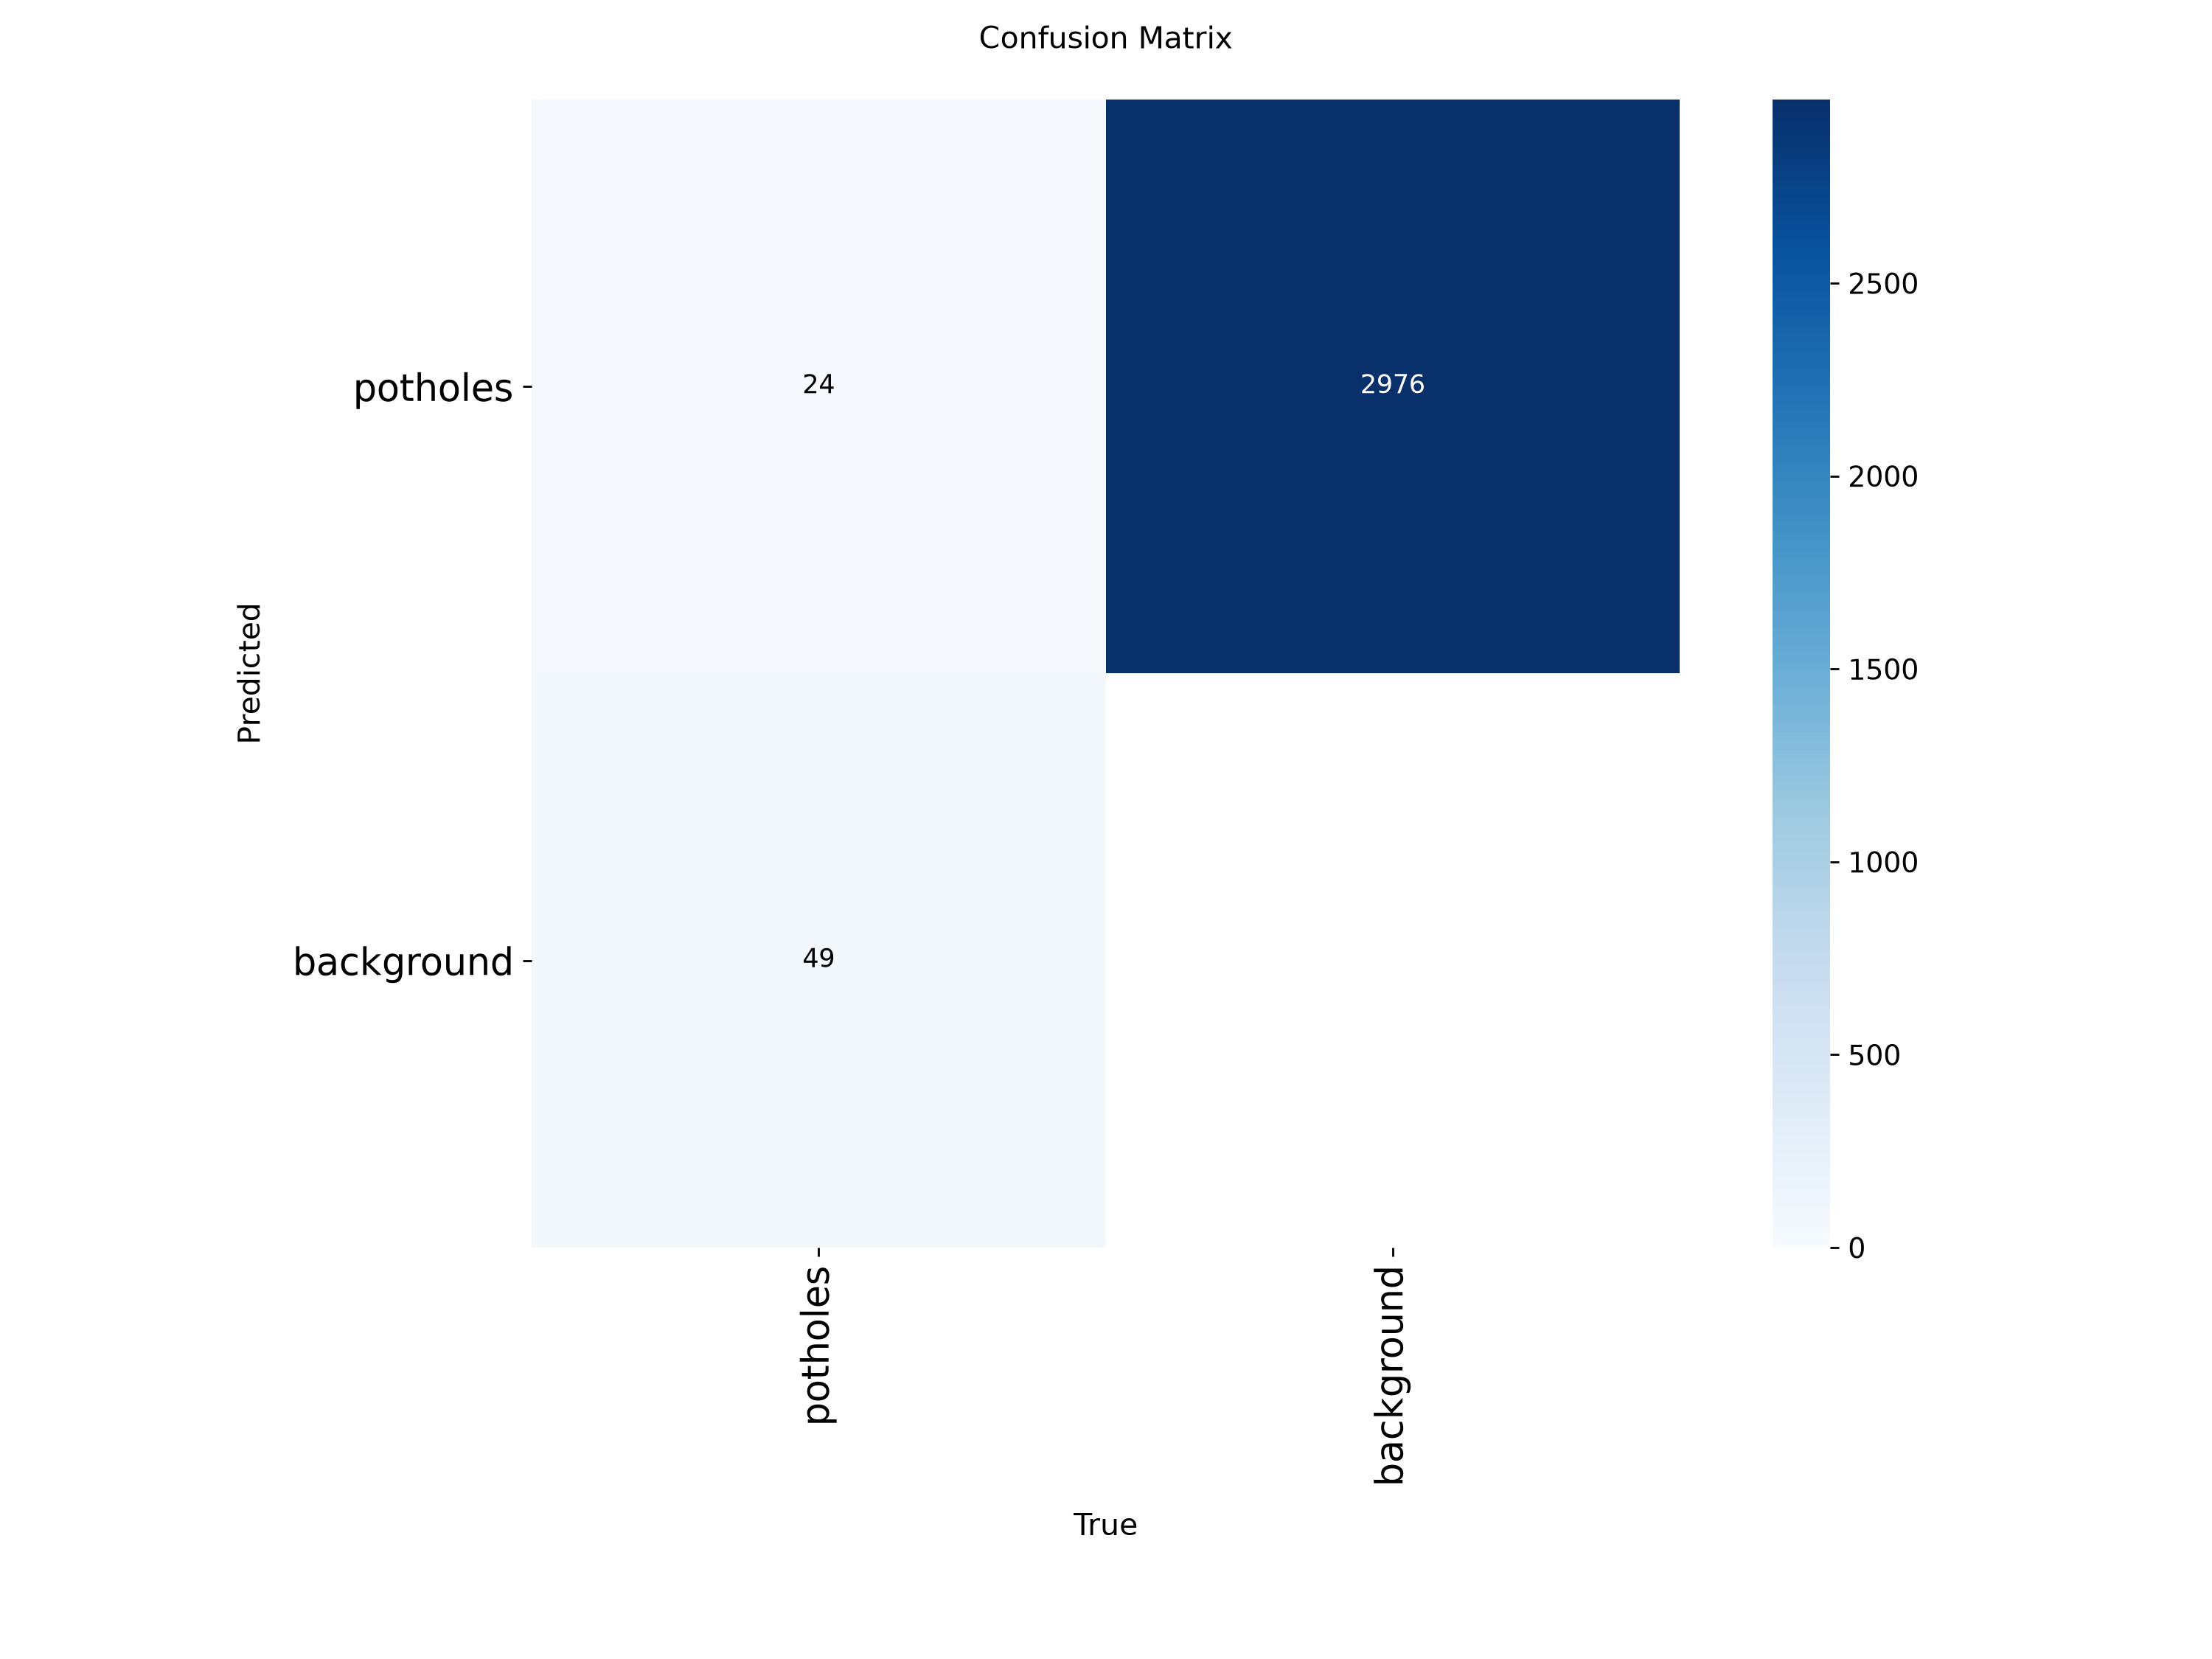

In [19]:
#untuk menampilkan confusion matrix
%cd {HOME}

#tampilkan confusion matrix hasil training
Image(filename=f'{HOME}/runs/detect/train-2/confusion_matrix.png', width=900)

/content/drive/MyDrive/Collab_Notebook/Machine_Learning_YOLO/Deteksi_Jalan_Berlubang


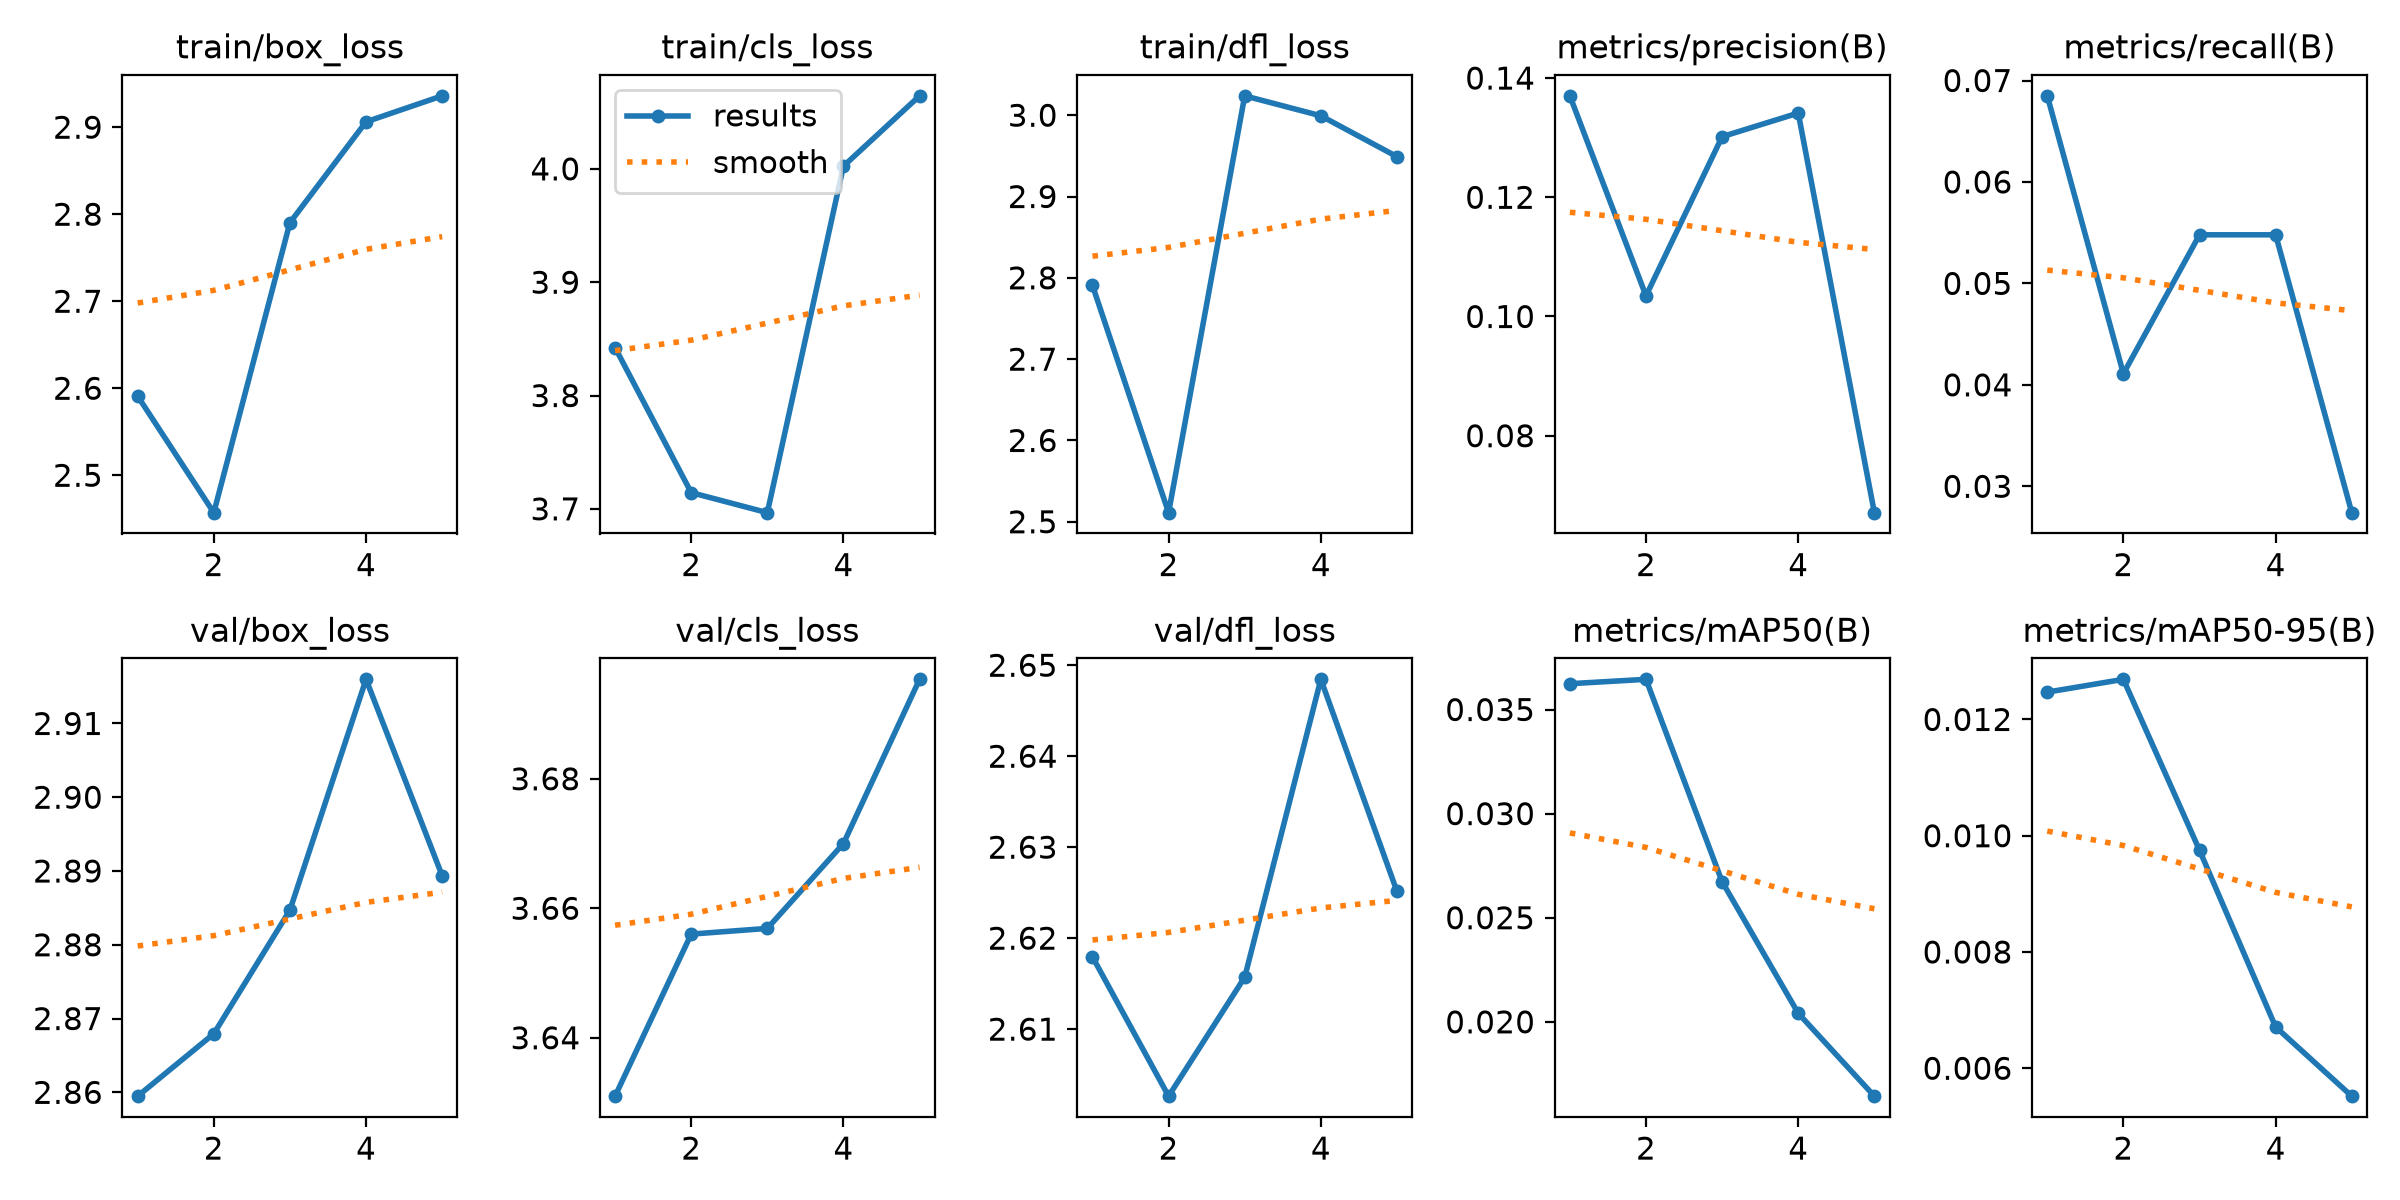

In [20]:
#pindah ke direktori project
%cd {HOME}

#tampilkan grafik hasil training yolov8
Image(filename=f'{HOME}/runs/detect/train-2/results.png', width=600)

/content/drive/MyDrive/Collab_Notebook/Machine_Learning_YOLO/Deteksi_Jalan_Berlubang


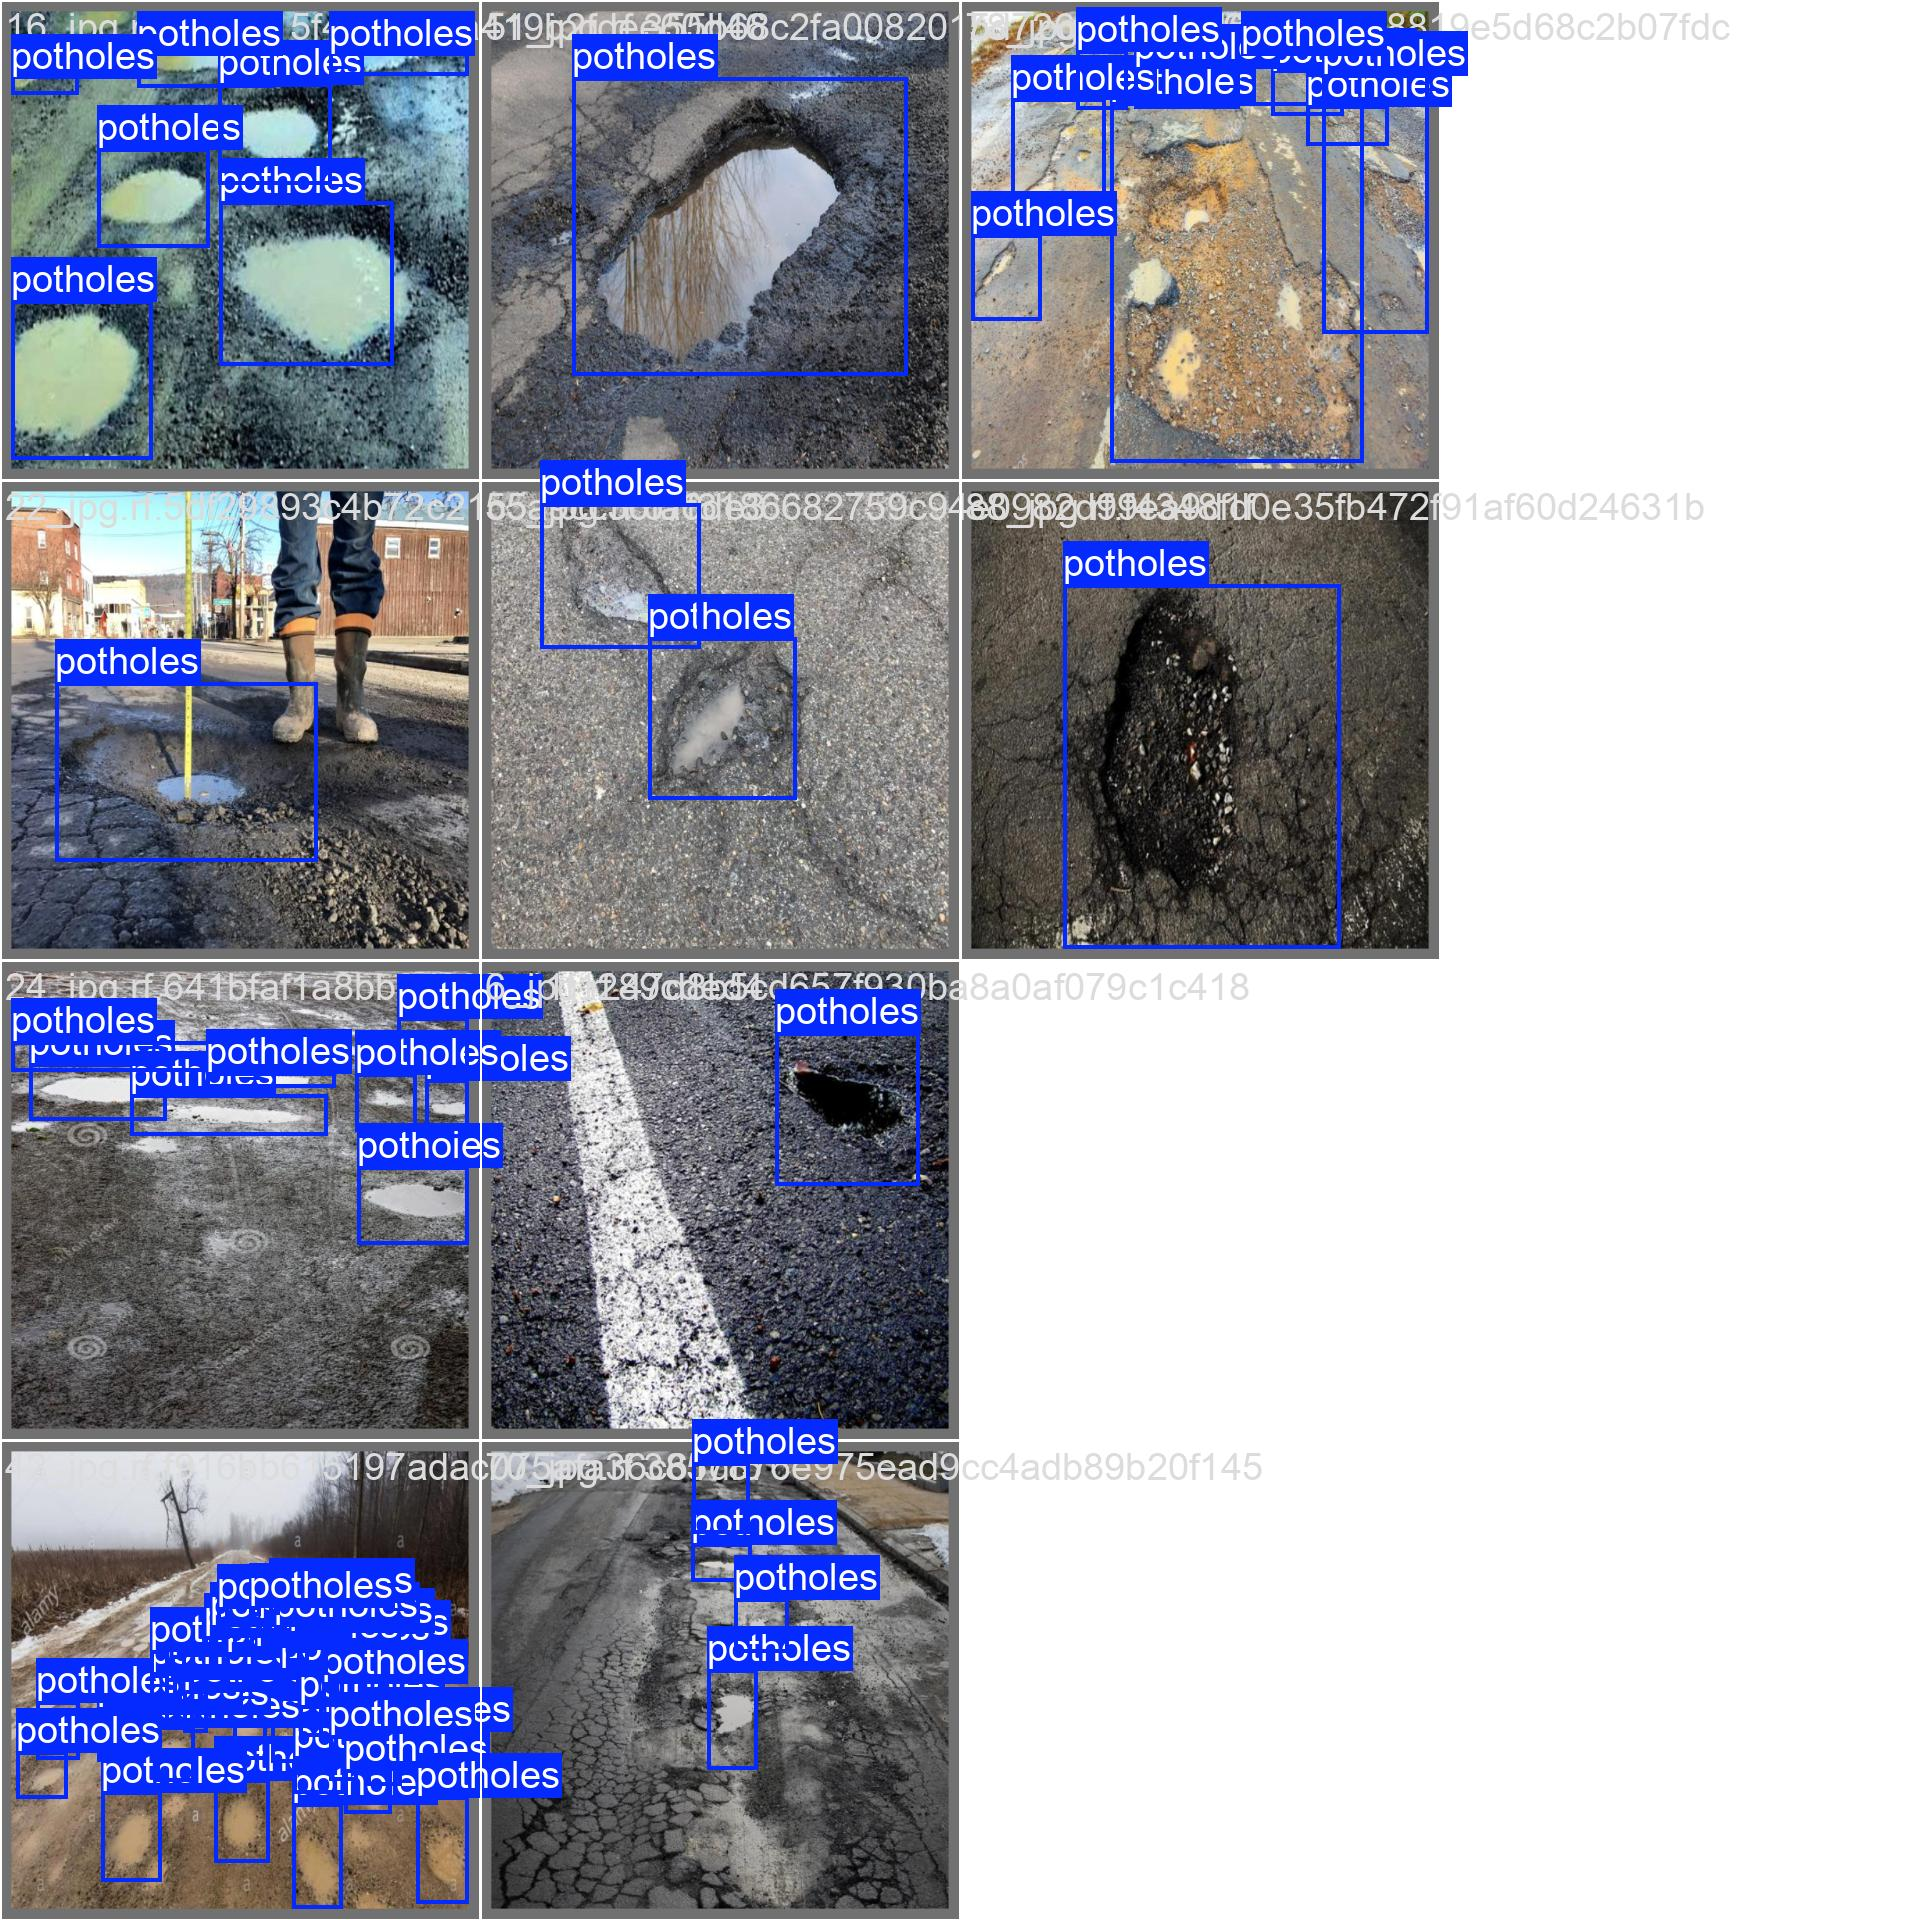

In [21]:
#prediksi model pada batch validasi
#gambar-gambar ini tidak di gunakan secara khusus untuk pelatihan
#pindah ke direktori
%cd {HOME}
#tampilkan hasil prediksi model di batch validasi
Image(filename=f'{HOME}/runs/detect/train-2/val_batch0_labels.jpg', width=900)

In [22]:
#validasi custom model

#pindah ke direktori
%cd {HOME}

#jalankan validasi model dengan bobot terbaik
!yolo task=detect mode=val model={HOME}/runs/detect/train-2/weights/best.pt data={HOME}/Jalan-Berlubang-1/data.yaml

/content/drive/MyDrive/Collab_Notebook/Machine_Learning_YOLO/Deteksi_Jalan_Berlubang
Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.15.0+cu132 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 92 layers, 25,840,339 parameters, 0 gradients, 78.7 GFLOPs
val: Fast image access ✅ (ping: 0.5±0.1 ms, read: 57.3±7.9 MB/s, size: 68.4 KB)
val: Scanning /content/drive/MyDrive/Collab_Notebook/Machine_Learning_YOLO/Deteksi_Jalan_Berlubang/Jalan-Berlubang-1/valid/labels.cache... 10 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 10/10 1.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 1.8it/s 0.6s
                   all         10         73      0.104     0.0411     0.0363     0.0125
Speed: 0.5ms preprocess, 33.2ms inference, 0.0ms loss, 2.3ms postprocess per image
Results saved to /content/drive/MyDrive/Collab_Notebook/Machine_Learning_YOLO/Deteksi_Jalan_Berlubang/runs/detect/val
💡 Learn more at https://docs.ultralytics

In [23]:
#menguji model pada dengan dataset uji
%cd {HOME}
!yolo task=detect mode=predict model={HOME}/runs/detect/train-2/weights/best.pt conf=0.25 source={HOME}/Jalan-Berlubang-1/test/images

/content/drive/MyDrive/Collab_Notebook/Machine_Learning_YOLO/Deteksi_Jalan_Berlubang
Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.15.0+cu132 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 92 layers, 25,840,339 parameters, 0 gradients, 78.7 GFLOPs

image 1/6 /content/drive/MyDrive/Collab_Notebook/Machine_Learning_YOLO/Deteksi_Jalan_Berlubang/Jalan-Berlubang-1/test/images/26_jpg.rf.998bbf8b3b94b9ba41a1207044e9bfd7.jpg: 640x640 (no detections), 36.9ms
image 2/6 /content/drive/MyDrive/Collab_Notebook/Machine_Learning_YOLO/Deteksi_Jalan_Berlubang/Jalan-Berlubang-1/test/images/53_jpg.rf.18c09a9f705b20dd660ff12f91847117.jpg: 640x640 (no detections), 36.9ms
image 3/6 /content/drive/MyDrive/Collab_Notebook/Machine_Learning_YOLO/Deteksi_Jalan_Berlubang/Jalan-Berlubang-1/test/images/56_jpg.rf.878adea88f4c3b399ba642bfa94f5df6.jpg: 640x640 1 potholes, 666.8ms
image 4/6 /content/drive/MyDrive/Collab_Notebook/Machine_Learning_YOLO/Deteksi_Jalan_Berlubang/Jalan-Berlubang-1/test/images/5_jpg.rf.d62

In [24]:
import os
pred_path = f"{HOME}/runs/detect/predict"
os.listdir(pred_path)

['26_jpg.rf.998bbf8b3b94b9ba41a1207044e9bfd7.jpg',
 '53_jpg.rf.18c09a9f705b20dd660ff12f91847117.jpg',
 '56_jpg.rf.878adea88f4c3b399ba642bfa94f5df6.jpg',
 '5_jpg.rf.d62eac8b29c0d4673e4c9290c708cb33.jpg',
 '65_jpg.rf.507d7b244d50c1703434ab1f47458f37.jpg',
 '71_jpg.rf.bde3eb579a90a02b16ba267cffa50173.jpg']

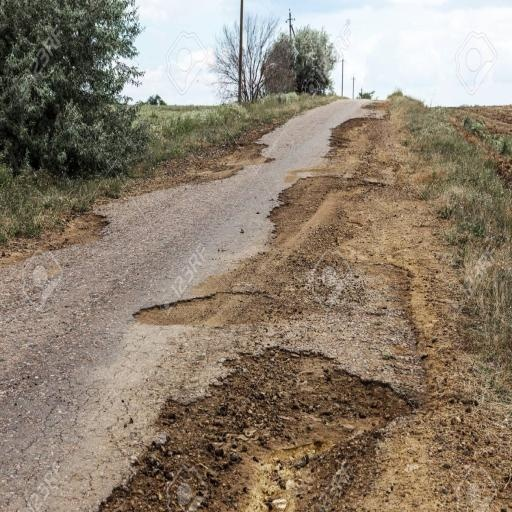

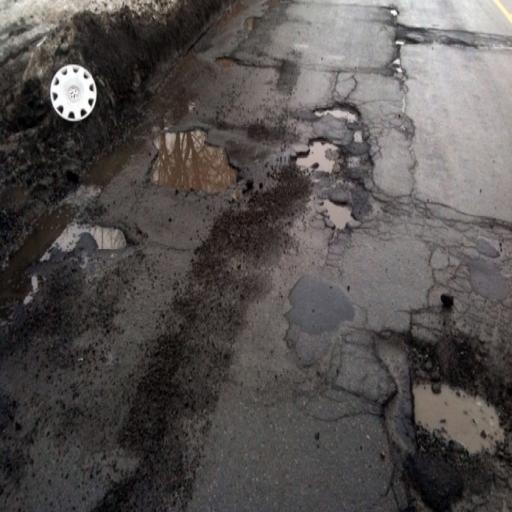

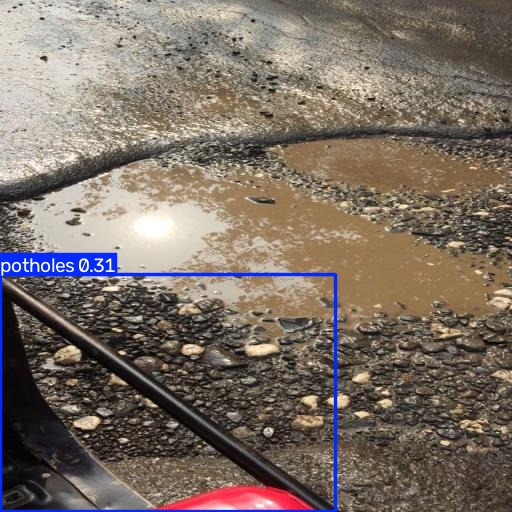

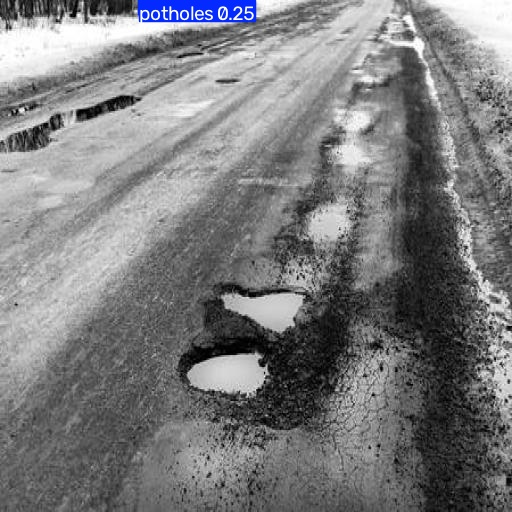

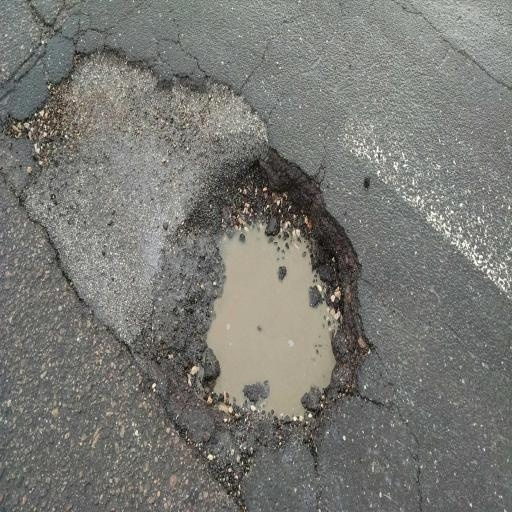

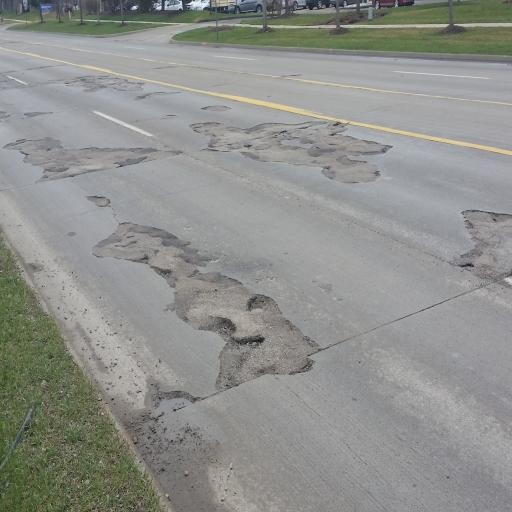

In [28]:
from IPython.display import Image, display
import glob

for img_path in glob.glob(f"{HOME}/runs/detect/predict/*"):
  display(Image(filename=img_path))

In [29]:
#pengujian demo
!gdown "https://www.youtube.com/shorts/anw3GrHkpEk"

Downloading...
From: https://www.youtube.com/shorts/anw3GrHkpEk
To: /content/drive/MyDrive/Collab_Notebook/Machine_Learning_YOLO/Deteksi_Jalan_Berlubang/anw3GrHkpEk
1.80MB [00:02, 865kB/s]
